# Парсинг вакансій та аналіз навичок Data Scientist: Від збору даних до інсайтів з українського тексту

У цьому уроці-майстер-класі ми зробимо один з типів Data Science проєктів, які зустрічаються в індустрії і який буде класним доповненням в Ваше портфоліо. 

**Задача:** Виявити, які конкретні навички прямо зараз є актуальними на ринку в обраному напрямі. В нашому випадку, Data Science.

Для цього нам необхідно
- Зібрати актуальні вакансії;
- Проаналізувати текст вакансій;
- Виявити навички в вакансіях;
- Зробити висновки.

В ході виконання завдання ми
- навчимося автоматично збирати дані з вебсайту (ця процедера називається "парсинг") за допомогою бібліотеки `selenium`;
- побудуємо візуалізацію WordCloud для аналізу текстів;
- познайомимось з поняттям n-грамів в обробці природньої мови;
- використаємо ChatGPT за АРІ аби "почистити" тексти вакансії від зайвої інформації і проставити лейбли для вакансій.

Збирати актуальні вакансії будемо в сфері Data Science з ресурсу DOU.ua, працюватимемо з українською та англіською мовами, та в результаті визначимо, які навички є найбільш затребуваними для фахівців з даних (data scientist).

В цьому уроці ми будемо працювати з web-сторінками, тому нам треба познайомитись з поняттям HTML.

## Коротке інтро, що таке HTML

**HTML (HyperText Markup Language)** — це стандартна мова розмітки, яка використовується для створення та структурування контенту вебсторінок в інтернеті. Вона дозволяє розмічати текст і додавати до нього різні елементи, такі як заголовки, абзаци, зображення, посилання, форми тощо.

Основні поняття HTML:

1. **Теги:**  
   HTML використовує теги для позначення різних елементів сторінки. Теги обмежуються кутовими дужками (`< >`) і зазвичай мають початковий і завершальний вигляд, наприклад:
   ```html
   <p>Це абзац тексту.</p>
   ```
   Деякі теги можуть бути самозакритими, наприклад, для зображень:
   ```html
   <img src="image.jpg" alt="Опис зображення" />
   ```

2. **Атрибути:**  
   Теги можуть містити атрибути, які надають додаткову інформацію про елемент. Наприклад, атрибут `src` вказує на джерело зображення, а `alt` описує його.
   ```html
   <img src="logo.png" alt="Логотип компанії" />
   ```

3. **Елементи:**  
   Елемент HTML складається з відкриваючого тегу, контенту та закриваючого тегу. Елементи можуть містити текст або інші елементи (вкладені елементи).
   ```html
   <h1>Заголовок сторінки</h1>
   ```

4. **Документна структура:**  
   Типовий HTML-документ має структуру з таких основних елементів:
   - `<!DOCTYPE html>` — вказує на тип документа.
   - `<html>` — кореневий тег документа.
   - `<head>` — містить метадані сторінки (стилі, метаінформація, скрипти).
   - `<body>` — містить видимий контент сторінки (текст, зображення, форми тощо).

   Наприклад:
   ```html
   <!DOCTYPE html>
   <html lang="uk">
     <head>
       <meta charset="UTF-8">
       <title>Назва сторінки</title>
     </head>
     <body>
       <h1>Вітаємо на нашому сайті!</h1>
       <p>Це перший абзац на сторінці.</p>
     </body>
   </html>
   ```

**Основна функція HTML** — це визначення структури і зовнішнього вигляду вебсторінки, яка потім відображається браузером. А от для додавання стилів (CSS) або інтерактивності (JavaScript) використовуються інші мови.

In [26]:
import os
import re
import time
from collections import Counter

import chromedriver_autoinstaller as chromedriver
import matplotlib.pyplot as plt
import nltk
import pandas as pd
import requests
from bs4 import BeautifulSoup
from dotenv import load_dotenv
from nltk import ngrams, word_tokenize
from nltk.corpus import stopwords
from nltk.util import bigrams
from openai import OpenAI
from selenium import webdriver
from selenium.webdriver.common.by import By
from tqdm import tqdm
from wordcloud import WordCloud

from ml_homework.paths import PROJECT_ROOT, STOPWORDS_PATH

In [27]:
chromedriver.install()
nltk.download("stopwords")
nltk.download("punkt_tab")

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/olharyzha/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/olharyzha/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

Зараз ми будемо парсити сторінку з вакансіями для Data Science, використовуючи бібліотеку Selenium. Першим кроком є відкриття вебсторінки, яка містить ці вакансії, за допомогою вебдрайвера Chrome. Для цього ми ініціалізуємо драйвер і вказуємо йому відкрити URL-адресу сторінки з вакансіями на DOU. 



In [28]:
driver = webdriver.Chrome()

driver.get("https://jobs.dou.ua/vacancies/?category=Data+Science")


На цьому етапі наш драйвер завантажує HTML-код сторінки, що дає нам можливість витягувати з нього необхідну інформацію. Далі ми будемо шукати конкретні елементи на сторінці, такі як заголовки вакансій, вимоги та інші деталі, і зберігати їх для подальшого аналізу.

Ми реалізуємо механізм для автоматичного завантаження більшої кількості вакансій на сторінці. Більшість сайтів, включаючи DOU, не показують всі вакансії одразу, тому користувачу потрібно натискати кнопку "Завантажити більше", щоб відобразити додаткові вакансії. Ми імітуємо дії користувача з `selenium`. І для цього робимо цикл:
1. У кожній ітерації циклу ми шукаємо елемент на сторінці, який відповідає кнопці для завантаження додаткових вакансій.
2. Після кожного кліка ми додаємо паузу в 3 секунди, щоб дати сторінці час на завантаження нових вакансій.
3. Якщо на сторінці більше немає кнопки "Завантажити більше" або виникає інша помилка (наприклад, елемент не знайдено), виконання програми перехоплює виключення, виводить повідомлення про завершення і виходить з циклу. 

In [29]:
while True:
    try:
        driver.find_element(By.CSS_SELECTOR, "div.more-btn a").click()
        time.sleep(3)
    except Exception as ex:
        print(ex)
        print("End.")
        break

Message: element not interactable
  (Session info: chrome=157.0.8103.52); For documentation on this error, please visit: https://www.selenium.dev/documentation/webdriver/troubleshooting/errors#elementnotinteractableexception
Stacktrace:
0   chromedriver                        0x0000000100b7f284 chromedriver + 3060356
1   chromedriver                        0x0000000100eddf98 __crubit_thunk_3b7060de5b04864c__uRNvNtCs56ojWEWzMFk_u16web_upackage_urust6parser23parse_umagic_uand_uversion + 153628
2   chromedriver                        0x0000000100f156b4 __crubit_thunk_3b7060de5b04864c__uRNvNtCs56ojWEWzMFk_u16web_upackage_urust6parser23parse_umagic_uand_uversion + 380728
3   chromedriver                        0x0000000100f0daa8 __crubit_thunk_3b7060de5b04864c__uRNvNtCs56ojWEWzMFk_u16web_upackage_urust6parser23parse_umagic_uand_uversion + 348972
4   chromedriver                        0x0000000100ec34fc __crubit_thunk_3b7060de5b04864c__uRNvNtCs56ojWEWzMFk_u16web_upackage_urust6parser23parse

На цьому етапі ми провантажили весь перелік вакансій обраної категорії і можемо завантажити їх у змінну.

Для зручності подальшої роботи ми використовуємо бібліотеку `BeautifulSoup`, яка має багато різного фукнціоналу для роботи з контентом в форматі html.

У даному випадку, `BeautifulSoup` виконує наступні дії:

1. **Парсинг HTML-контенту:**  
   Коли ми викликаємо `BeautifulSoup(content)`, бібліотека обробляє весь HTML-код, отриманий від вебдрайвера (`driver.page_source`). Вона перетворює його у зручний для роботи формат дерева, що дозволяє легко шукати та витягувати елементи сторінки.

2. **Створення об'єкта для подальшого аналізу:**  
   `soup` — це об'єкт, який містить всю структуру HTML. З його допомогою можна виконувати подальші операції: знаходити конкретні елементи сторінки, витягувати текстові дані, аналізувати посилання, таблиці, списки тощо.

Завдяки цьому ми можемо переходити до пошуку та витягування необхідної інформації зі сторінки, наприклад, посилань на вакансії, заголовків вакансій, вимог, імен компаній тощо.

In [30]:
content = driver.page_source
soup = BeautifulSoup(content)

У нас зараз вивантажена сторінка з усіма вакансіями і ми хочемо взяти посилання кожної з вакансій аби потім провантажити сторінки з описами вакансій. Для цього пишемо код, який шукає в html сторінки посилання на вакансії.

In [31]:
vac_list = soup.findAll("a", href=True, attrs={"class": "vt"})
project_href = [i["href"] for i in vac_list]

/var/folders/sf/n0z72hys1y135d8_9m48bfvh0000gn/T/ipykernel_99929/888149317.py:1: DeprecationWarning: Call to deprecated method findAll. (Replaced by find_all) -- Deprecated since version 4.0.0.
  vac_list = soup.findAll("a", href=True, attrs={"class": "vt"})


І такий результат ми отримали:

In [32]:
len(project_href)

33

In [33]:
project_href

['https://jobs.dou.ua/companies/trementum-analytics/vacancies/201933/',
 'https://jobs.dou.ua/companies/obrio/vacancies/362752/',
 'https://jobs.dou.ua/companies/megogonet-/vacancies/379404/',
 'https://jobs.dou.ua/companies/a-listware/vacancies/379321/',
 'https://jobs.dou.ua/companies/intellias/vacancies/379125/',
 'https://jobs.dou.ua/companies/softserve/vacancies/359400/',
 'https://jobs.dou.ua/companies/sigma-software/vacancies/379013/',
 'https://jobs.dou.ua/companies/evowill/vacancies/378850/',
 'https://jobs.dou.ua/companies/mycredit/vacancies/378827/',
 'https://jobs.dou.ua/companies/dataforest/vacancies/378677/',
 'https://jobs.dou.ua/companies/quantum/vacancies/375425/',
 'https://jobs.dou.ua/companies/mycredit/vacancies/366993/',
 'https://jobs.dou.ua/companies/mycredit/vacancies/370502/',
 'https://jobs.dou.ua/companies/proxet/vacancies/378005/',
 'https://jobs.dou.ua/companies/insart/vacancies/377983/',
 'https://jobs.dou.ua/companies/epam-systems/vacancies/377879/',
 'ht

Тепер нам треба завантажити кожне з цих посилань та взяти з них текст вакансій.

In [34]:
headers = {"User-Agent": "HTTPie/3.1.0"}

In [35]:
vacs = {"link": [], "name": [], "desc": []}
for link in tqdm(project_href):
    page = requests.get(link, headers=headers)
    soup = BeautifulSoup(page.content, "html.parser")
    vacs["link"].append(link)
    vacs["name"].append(soup.title.text)
    vacs["desc"].append(soup.select("div.vacancy-section")[0].text)
    time.sleep(1)

100%|██████████| 33/33 [00:42<00:00,  1.29s/it]


In [36]:
len(vacs["link"])

33

Далі вже все просто: записуємо результат в датафрейм і використовуємо для подальших цілей.

In [37]:
df = pd.DataFrame(vacs)

In [38]:
df.head()

,link,name,desc
0,https://jobs.dou.ua/companies/trementum-analyt...,Trainee/Junior Data Analyst в Trementum Resear...,\nWe are looking for talented career starters ...
1,https://jobs.dou.ua/companies/obrio/vacancies/...,"Senior/Lead Data Scientist в OBRIO, Київ, Льві...","\nПривіт!Ми OBRIO — команда, яка завжди хоче б..."
2,https://jobs.dou.ua/companies/megogonet-/vacan...,"Data Science Tech Lead в MEGOGO, Київ, віддале...",\nЦе hands-on Tech Lead роль із фокусом на мул...
3,https://jobs.dou.ua/companies/a-listware/vacan...,Senior Data Scientist (AdTech / RTB / Programm...,\nOur Customer:Our customer is a technology co...
4,https://jobs.dou.ua/companies/intellias/vacanc...,"ETL System/Data Analyst в Intellias, віддалено...",\nLet’s breathe life into great tech ideas! Wi...


In [39]:
df.to_csv("data_science_vacs.csv", index=False)

In [40]:
print(df.desc.loc[1])


Привіт!Ми OBRIO — команда, яка завжди хоче більшого: від себе, від життя, від роботи. Якщо тобі теж замало «достатньо добре» — ти вже розумієш, про що ми. Тут сильні люди притягують сильних — і разом ми розвиваємо компанію, що будує продукт № 1 у ніші spiritual wellness — Nebula.Зараз ми шукаємо Senior/Lead Data Scientist в напрямок Marketing Analytics.Ти будуватимеш прогнозні моделі, що безпосередньо впливають на рішення про маркетингові інвестиції, монетизацію та розвиток маркетплейсу. Маркетинг — це двигун нашого бізнесу, а точність прогнозів — ядро того, як ми приймаємо рішення на мільйони доларів. Твій вплив буде прямим: від якості моделей залежатиме, скільки ми заробляємо і від яких ризиків захищені.У команді ти матимеш можливість попрацювати з маркетинговими аналітиками, Data Engineers та Data Analysts, а також з продуктовими менеджерами і стейкхолдерами з маркетингу, пейментів і продукту — залежно від задачі.Твоїм безпосереднім менеджером буде Дмитро Авраменко, Head of Analyti

# Visualize

Наша задача зараз - зрозуміти, що хочуть бачити в Data Scientists зараз. Для цього давайте візуалізуємо дані в вигляді WordCloud.

## WordCloud
**WordCloud (хмара слів)** — це візуалізація текстових даних, яка показує найбільш часто використовувані слова в тексті. У такій візуалізації кожне слово має свій розмір, що відповідає його частоті в тексті: чим частіше слово зустрічається, тим більшим шрифтом воно відображається в хмарі слів. Хмара слів часто використовується в аналізі великих текстових корпусів, таких як новини, соціальні медіа, наукові публікації та інші джерела, щоб швидко зрозуміти ключові теми.

Основні характеристики WordCloud:
1. **Частотність слів:**  
   Найбільш поширені слова у тексті займають більше місця в хмарі і відображаються великим шрифтом, менш поширені — меншим.
   
2. **Візуальна інтерпретація:**  
   Хмара слів дозволяє швидко зрозуміти основні теми або ключові поняття в тексті, оскільки найважливіші терміни виражені візуально.
   
3. **Обробка тексту:**  
   Перед створенням хмари слів, текст зазвичай проходить обробку: видаляються стоп-слова (наприклад, "і", "в", "на"), знаки пунктуації, числа та інші незначні елементи.

### Приклад:
Якщо ви аналізуєте набір вакансій для Data Scientists, хмара слів може показати найбільш важливі навички та інструменти, такі як "Python", "Machine Learning", "Data", "SQL" тощо, допомагаючи виявити ключові вимоги до кандидатів.

Для створення хмари слів можна використовувати бібліотеку `WordCloud`:

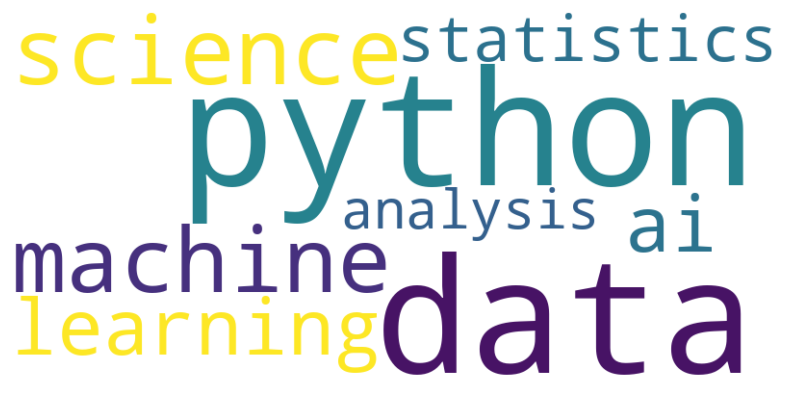

In [41]:
# Текст для аналізу
text = "data science python machine learning ai statistics python analysis data"

# Створення хмари слів
wordcloud = WordCloud(width=800, height=400, background_color="white").generate(text)

# Відображення хмари слів
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()

Тепер побудуємо WordCloud для нашого набору даних з описами вакансій.

In [42]:
df = pd.read_csv("data_science_vacs.csv")

Давайте видалимо стоп-слова. Тут у нас зустрічаються українські тексти в тому числі, і завантажити стопслова для української ми можемо звідси: https://github.com/skupriienko/Ukrainian-Stopwords

In [43]:
stopwords_ua = pd.read_csv(
    STOPWORDS_PATH / "stopwords_ua.txt", header=None, names=["stopwords"]
)
stopwords_ua = list(stopwords_ua.stopwords)

In [44]:
stopwords_list = stopwords_ua + stopwords.words("english")

In [45]:
text = "\n".join(df.desc.tolist())

In [46]:
len(text)

135622

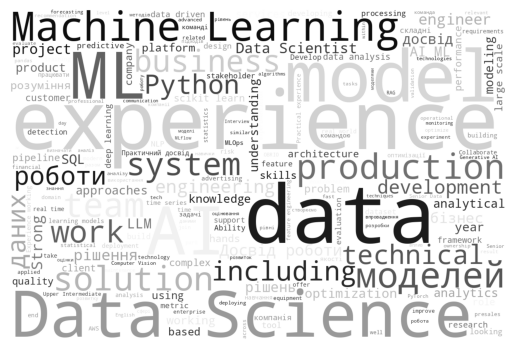

In [47]:
def create_wordcloud(text, stopwords_list):
    wc = WordCloud(
        background_color="white",
        colormap="binary",
        stopwords=stopwords_list,
        width=1200,
        height=800,
    ).generate(text)
    plt.axis("off")
    plt.imshow(wc)


create_wordcloud(text, stopwords_list)

Непогано, але можна краще.
Ця хмара слів частково відображає основні поняття, які можуть бути корисними для Data Scientist, такі як "Python", "machine learning", "NLP", "data", "model", "experience", "team". Вона дає загальне уявлення про те, що є важливим у вакансіях, але не забезпечує точного фокусу на конкретних навичках, що нам було б найцікавіше знати в такому аналізі.

Проблеми з поточною хмарою слів:
1. **Невизначеність ключових слів:**  
   У хмарі з'являються слова, які не відносяться безпосередньо до навичок, наприклад, "company", "team", "work", "experience", "product". Ці слова є занадто загальними і не дають корисної інформації про технічні чи аналітичні навички, які потребує Data Scientist.

2. **Мікс термінів:**  
   Хмара слів містить як технічні терміни (наприклад, "Python", "SQL", "machine learning"), так і загальні терміни, що можуть бути частиною опису вакансії, але не є навичками ("company", "development", "team").

   
Давайте проведемо додаткову обробку аби витягнути саме навички.

## Extract skills

Використаємо Groq API для виділення вимог до кандидата з описів вакансій. Ключ, адреса API та назва моделі (`LLM_MODEL`) зберігаються у файлі `.env` у корені проєкту.


In [48]:
load_dotenv(PROJECT_ROOT / ".env")
api_url = os.environ["LLM_API_URL"].rstrip("/")
client = OpenAI(api_key=os.environ["LLM_API_KEY"], base_url=api_url)

In [49]:
llm_model_used = os.environ["LLM_MODEL"]
max_tokens = 4096


def generate_messages(system_content, user_content):
    return [
        {"role": "system", "content": system_content},
        {"role": "user", "content": user_content},
    ]


def get_llm_response(messages, temperature=0, max_tokens=max_tokens, top_p=1):
    return client.chat.completions.create(
        model=llm_model_used,
        messages=messages,
        temperature=temperature,
        # max_tokens=max_tokens,
        top_p=top_p,
    )

In [50]:
print(df.desc.loc[0])


We are looking for talented career starters to join the Trementum team. The programme allows you to discover yourself through real challenges and gain portable skills from projects within the following areas: Analytics, Data Science, Data Visualisation, and Software Development. Our projects include: — Reports for NATO StratCom — Public interest researchWhat you’ll be doing:support us in researching relevant data sources and data analysishelp us to collect and carefully process data (data cleaning/data pre-processing)support, where necessary, also with manual data collection and processingwork on data analysis and data visualisationsupport us in day-to-day operationsWhat we are looking for:An analytical mindset: desire to crunch numbers and be responsible for the analysis precisionFast learners: open to learning and using new toolsMotivation: interest in current political, technological and social developments and debatesBasic SQL/Python/pandasA committed team playerBonus points (not 

Задамо промпт, який дозволить нам прибрати все, що не стосується безпосередньо опису навичок кандидата.

In [51]:
prompt = """
You are provided with a technical vacancy description either in English or in Ukrainian. 
Extract only skills required for a candidate and the responsibilities. Return the extracted part 
as a plain text.
Vacancy:
{}
"""
system_content = ""

In [52]:
generate_messages(system_content, prompt.format(df.desc.loc[0]))

[{'role': 'system', 'content': ''},
 {'role': 'user',
  'content': '\nYou are provided with a technical vacancy description either in English or in Ukrainian. \nExtract only skills required for a candidate and the responsibilities. Return the extracted part \nas a plain text.\nVacancy:\n\nWe\xa0are looking for talented career starters to\xa0join the Trementum team. The programme allows you to\xa0discover yourself through real challenges and gain portable skills from projects within the following areas: Analytics, Data Science, Data Visualisation, and Software Development. Our projects include: —\xa0Reports for NATO StratCom —\xa0Public interest researchWhat you’ll be\xa0doing:support\xa0us in\xa0researching relevant data sources and data analysishelp\xa0us to\xa0collect and carefully process data (data cleaning/data pre-processing)support, where necessary, also with manual data collection and processingwork on\xa0data analysis and data visualisationsupport\xa0us in\xa0day-to-day operat

In [53]:
response = get_llm_response(
    generate_messages(system_content, prompt.format(df.desc.loc[0]))
)

In [54]:
response

ChatCompletion(id='chatcmpl-036f9dfa-81d9-4bdc-9e55-339470ec59c2', choices=[Choice(finish_reason='stop', index=0, logprobs=None, message=ChatCompletionMessage(content='**Responsibilities**  \n- Research relevant data sources and perform data analysis.  \n- Collect and carefully process data (data cleaning / data pre‑processing).  \n- Assist with manual data collection and processing when needed.  \n- Work on data analysis and data visualisation.  \n- Support day‑to‑day operations.  \n\n**Required Skills**  \n- Analytical mindset with a focus on precision in analysis.  \n- Fast learner, open to learning and using new tools.  \n- Motivation and interest in current political, technological, and social developments and debates.  \n- Basic proficiency in SQL, Python, and pandas.  \n- Committed team player.  \n\n**Bonus (optional) Skills**  \n- Knowledge of data mining and text‑processing techniques.  \n- Familiarity with databases and Unix systems.', refusal=None, role='assistant', annotati

In [55]:
response_text = response.model_dump()["choices"][0]["message"]["content"]

In [56]:
print(response_text)

**Responsibilities**  
- Research relevant data sources and perform data analysis.  
- Collect and carefully process data (data cleaning / data pre‑processing).  
- Assist with manual data collection and processing when needed.  
- Work on data analysis and data visualisation.  
- Support day‑to‑day operations.  

**Required Skills**  
- Analytical mindset with a focus on precision in analysis.  
- Fast learner, open to learning and using new tools.  
- Motivation and interest in current political, technological, and social developments and debates.  
- Basic proficiency in SQL, Python, and pandas.  
- Committed team player.  

**Bonus (optional) Skills**  
- Knowledge of data mining and text‑processing techniques.  
- Familiarity with databases and Unix systems.


In [57]:
# process all vacancies


def get_skills(vacancy):
    return get_llm_response(generate_messages(system_content, prompt.format(vacancy)))


df["skills"] = df.desc.apply(get_skills)

In [58]:
df["skills_text"] = df.skills.apply(
    lambda x: x.model_dump()["choices"][0]["message"]["content"]
)

In [59]:
print(df["desc"].loc[1])


Привіт!Ми OBRIO — команда, яка завжди хоче більшого: від себе, від життя, від роботи. Якщо тобі теж замало «достатньо добре» — ти вже розумієш, про що ми. Тут сильні люди притягують сильних — і разом ми розвиваємо компанію, що будує продукт № 1 у ніші spiritual wellness — Nebula.Зараз ми шукаємо Senior/Lead Data Scientist в напрямок Marketing Analytics.Ти будуватимеш прогнозні моделі, що безпосередньо впливають на рішення про маркетингові інвестиції, монетизацію та розвиток маркетплейсу. Маркетинг — це двигун нашого бізнесу, а точність прогнозів — ядро того, як ми приймаємо рішення на мільйони доларів. Твій вплив буде прямим: від якості моделей залежатиме, скільки ми заробляємо і від яких ризиків захищені.У команді ти матимеш можливість попрацювати з маркетинговими аналітиками, Data Engineers та Data Analysts, а також з продуктовими менеджерами і стейкхолдерами з маркетингу, пейментів і продукту — залежно від задачі.Твоїм безпосереднім менеджером буде Дмитро Авраменко, Head of Analyti

In [60]:
print(df["skills_text"].loc[1])

**Skills Required**

- 4+ years of experience in Data Science / Machine Learning, focused on predictive models with real business impact.  
- Strong proficiency in **Python** and **SQL**.  
- Expertise in **Time‑Series Forecasting**, **Gradient Boosting** models, and **Feature Engineering**.  
- Hands‑on experience with **MLOps** tools and practices: **Airflow**, **Docker**, **CI/CD**, real‑time scoring, and anomaly detection.  
- Ability to work in imperfect data environments: decompose problems, progress despite missing data or sub‑optimal architecture.  
- Excellent project‑management and stakeholder‑communication skills across multiple domains; ask the right questions and keep results aligned between teams.  
- End‑to‑end ownership: take a task from formulation through production and be accountable for the outcome, not just the model.  
- Familiarity with OBRIO’s AI‑centric workflow and tools (Claude, Cursor, CodeRabbit, OpenRouter, AWS Bedrock, NotebookLM, N8N, Gemini, OpenAI, Hey

In [61]:
df.to_csv("data_science_vacs_enriched.csv", index=False)
df = pd.read_csv("data_science_vacs_enriched.csv")

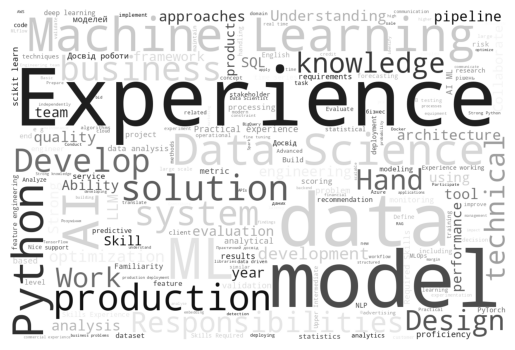

In [62]:
text = "\n".join(df.skills_text.tolist())
create_wordcloud(text, stopwords_list)

Все ще виглядає як трошки не то. Давайте зробимо користувацький препроцесинг. 
А для початку познайомимось з поняттям n-grams.

## Що таке N-грами

**N-grams** — це послідовності з n елементів (зазвичай слів або символів), які використовуються в обробці природної мови (NLP) для аналізу тексту. N може бути будь-яким цілим числом і вказує кількість елементів у послідовності.

### Типи n-grams:
1. **Unigram (1-gram):**  
   Це окремі слова або символи в тексті. Наприклад, у реченні "I love Python", уніграми будуть:
   - I
   - love
   - Python

2. **Bigram (2-gram):**  
   Це послідовності з двох слів або символів. Для того ж речення "I love Python", біграми будуть:
   - I love
   - love Python

3. **Trigram (3-gram):**  
   Це послідовності з трьох слів або символів. У реченні "I love Python", тріграми будуть:
   - I love Python

4. **N-grams:**  
   Якщо n більше трьох, це можуть бути, наприклад, 4-grams, 5-grams тощо.

### Для чого використовують N-grams:
1. **Аналіз тексту:**  
   N-grams використовуються для виявлення частих словосполучень або шаблонів в тексті. Це особливо корисно для розуміння структури тексту або для аналізу мови.

2. **Моделювання мови:**  
   N-grams допомагають прогнозувати наступне слово в реченні на основі попередніх слів. Це ключовий підхід у задачах, таких як автозаповнення тексту чи машинний переклад.

3. **Класифікація тексту:**  
   N-grams часто використовуються як ознаки для моделювання текстової класифікації, наприклад, у задачах аналізу настроїв або виявлення спаму.

4. **Аналіз послідовностей:**  
   N-grams можуть використовуватись для аналізу біологічних послідовностей (ДНК) або інших форм послідовних даних.

### Приклад коду в Python з використанням `nltk` для генерації біграм:


In [63]:
text = "I love Python programming"
tokens = nltk.word_tokenize(text)

# Генерація біграм
example_bigrams = list(ngrams(tokens, 2))
print(example_bigrams)

[('I', 'love'), ('love', 'Python'), ('Python', 'programming')]


Використаємо n-грами в нашому аналізі. В WordCloud за замовченням беруться до уваги unigrams and bigrams - можна в цьому переконатись в [сорс коді бібліотеки](https://github.com/amueller/word_cloud/blob/main/wordcloud/wordcloud.py#L598).

In [64]:
def clean_text(text):
    # Remove non-word characters
    text = re.sub(r"\W+", " ", text).lower()
    # Tokenize text
    tokens = word_tokenize(text)
    # Remove stopwords
    stop_words = set(stopwords.words("english"))
    cleaned_tokens = [word for word in tokens if word not in stop_words]
    # Join cleaned tokens back into a string
    return " ".join(cleaned_tokens)


tokens = word_tokenize(clean_text(text.lower()))  # Tokenize and convert to lower case
bigram_list = list(bigrams(tokens))
bigram_freq = Counter(bigram_list)

In [65]:
bigram_freq_d = dict(bigram_freq)

In [66]:
bigram_freq_d = {" ".join(k): v for k, v in bigram_freq_d.items()}

In [67]:
bigram_df = pd.DataFrame(bigram_freq_d.items(), columns=["bigram", "freq"])

In [68]:
bigram_df.sort_values(by="freq", ascending=False)[:30]

,bigram,freq
0,love python,1
1,python programming,1


In [69]:
df["contains llm"] = df.desc.str.lower().apply(
    lambda x: "llm" in x or "generative" in x
)

In [70]:
df["contains neural"] = df.desc.str.lower().apply(
    lambda x: "neural" in x or "deep" in x
)

In [71]:
df.to_csv("data_science_vacs_enriched.csv", index=False)

In [72]:
df["contains llm"].value_counts()

contains llm
False    22
True     11
Name: count, dtype: int64

In [73]:
df["contains neural"].value_counts()

contains neural
False    18
True     15
Name: count, dtype: int64

In [74]:
pd.options.display.max_columns = None
pd.options.display.max_rows = None
pd.options.display.max_colwidth = None

# df[df['contains llm']][['name','desc', 'link']]